# Experiments

Each experiment trains a model from scratch and is saved in `models/<name>/`.
Training uses the GPU when is available.

Every run reports Hits@20 on the training, validation and test splits after the last epoch.

In [1]:
!git clone https://github.com/AidaKhaleghi/Drug-Drug-Interaction_GNN.git

Cloning into 'Drug-Drug-Interaction_GNN'...
remote: Enumerating objects: 41, done.
remote: Counting objects: 100% (41/41), done.
remote: Compressing objects: 100% (28/28), done.
remote: Total 41 (delta 10), reused 38 (delta 7), pack-reused 0 (from 0)
Receiving objects: 100% (41/41), 1.47 MiB | 17.31 MiB/s, done.
Resolving deltas: 100% (10/10), done.


In [2]:
%cd Drug-Drug-Interaction_GNN
!pip install -e .
%cd src

/content/Drug-Drug-Interaction_GNN
Obtaining file:///content/Drug-Drug-Interaction_GNN
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 78.8/78.8 kB 4.9 MB/s eta 0:00:00
  Building editable for ddi-gnn (pyproject.toml) ... done
  Created wheel for ddi-gnn: filename=ddi_gnn-0.1.0-0.editable-py3-none-any.whl size=1361 sha256=f76a85b467e43e540a47f2c083c19c698074c38d946c695ad4f7c44ec56c55de
  Stored in directory: /tmp/pip-ephem-wheel-cache-_9m88b2x/wheels/63/fe/5a/b9cbc227ff9c228bfc5d2769fc7692465b22192c47fd5bf8b1
Successfully built ddi-gnn
/content/Drug-Drug-Interaction_GNN/src


In [3]:
from functools import partial
from pathlib import Path

import itertools

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import torch

from ddi_gnn.data import load_ddi
from ddi_gnn.plotting import plot_learning
from ddi_gnn.train import run_experiment
from ddi_gnn.utils import get_device

DATA_ROOT = "/content/datasets"
SAVE_DIR = "/content/models"

print(f"Training on: {get_device()}")

# Every run in this notebook saves to SAVE_DIR.
run = partial(run_experiment, save_dir=SAVE_DIR)

Training on: cuda


In [4]:
def summarize(metrics: pd.DataFrame) -> dict:
    """Returns the Hits@20 of each split after the last epoch."""
    hits = metrics[metrics["metric"] == "hits@20"].sort_values("epoch")
    return hits.groupby("split")["mean"].last().to_dict()

## Dataset

A random subset of 500 drugs keeps these experiments fast.

In [5]:
small_data = load_ddi(
    root=DATA_ROOT,
    node_limit=500,
    generator=torch.Generator().manual_seed(42),
)
print(f"{small_data.n_nodes} drugs, {len(small_data.splits['train'].pos)} training interactions")

Downloaded 0.04 GB: 100%|██████████| 46/46 [00:02<00:00, 15.56it/s]


Extracting /content/datasets/ddi.zip
Loading necessary files...
This might take a while.
Processing graphs...


100%|██████████| 1/1 [00:00<00:00, 46.44it/s]

Saving...


500 drugs, 17625 training interactions


## Baseline model

The simplest setting: binary log loss, no self-edge in the last layer, no degree normalization.

Epoch 500: 100%|██████████| 500/500 [00:27<00:00, 18.13it/s, hits@20: train=0.6107, valid=0.8716]


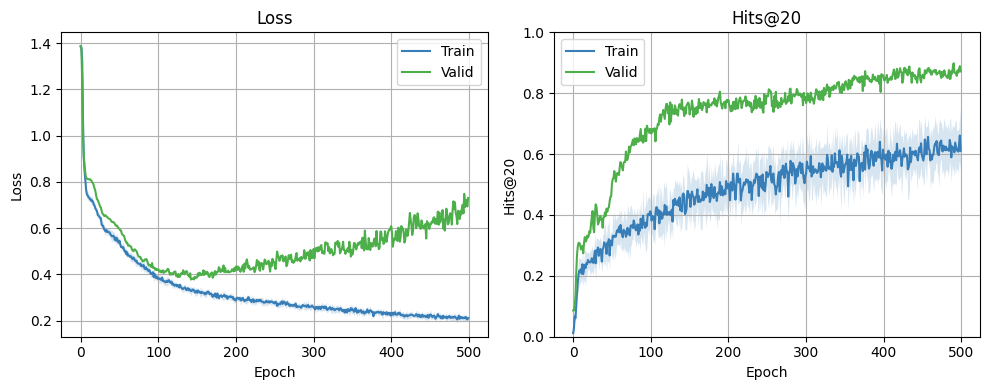

{'test': 0.7656766176223755,
 'train': 0.6106676856676737,
 'valid': 0.8716126084327698}

In [6]:
BASE_MODEL = {
    "embedding_dim": 128,
    "dropout_rate": 0.3,
    "last_layer_self": False,
    "degree_norm": False,
}

_, metrics = run(
    "baseline_bce", small_data, BASE_MODEL, loss="bce", num_epochs=500, eval_every=1
)
plot_learning(metrics)
plt.show()
summarize(metrics)

## Changing to the AUC loss

Epoch 500: 100%|██████████| 500/500 [00:26<00:00, 18.63it/s, hits@20: train=0.4695, valid=0.8627]


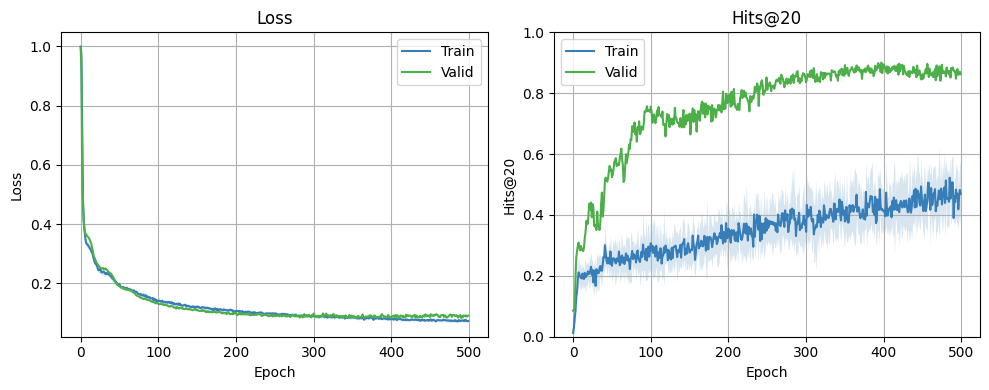

{'test': 0.8650990128517151,
 'train': 0.4695028132862515,
 'valid': 0.862727701663971}

In [7]:
_, metrics = run(
    "baseline_auc", small_data, BASE_MODEL, loss="auc", num_epochs=500, eval_every=1
)
plot_learning(metrics)
plt.show()
summarize(metrics)

## Varying the embedding dimension

In [8]:
rows = []
for embedding_dim in [64, 128, 256, 512]:
    _, metrics = run(
        f"sweep_embedding_dim_{embedding_dim}",
        small_data,
        {**BASE_MODEL, "embedding_dim": embedding_dim},
        loss="auc",
    )
    rows.append({"embedding_dim": embedding_dim, **summarize(metrics)})

embedding_results = pd.DataFrame(rows)
embedding_results

Epoch 500: 100%|██████████| 500/500 [00:43<00:00, 11.41it/s, hits@20: train=0.9939, valid=0.6952]


,embedding_dim,test,train,valid
0,64,0.811469,0.288941,0.833407
1,128,0.823432,0.433478,0.848512
2,256,0.734323,0.696236,0.877832
3,512,0.567657,0.993907,0.695247


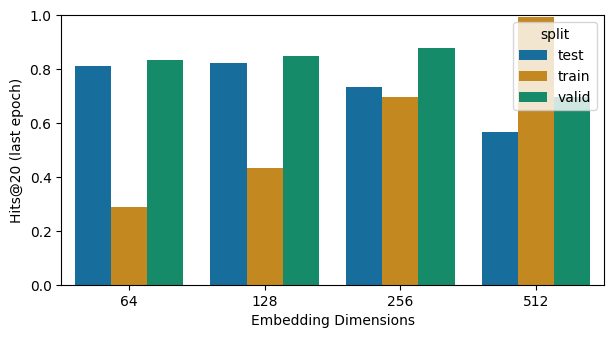

In [9]:
data = embedding_results.melt(
    id_vars="embedding_dim", var_name="split", value_name="hits@20"
)

plt.figure(figsize=(7, 3.5))
sns.barplot(data=data, x="embedding_dim", y="hits@20", hue="split", palette="colorblind")
plt.ylim(0, 1)
plt.xlabel("Embedding Dimensions")
plt.ylabel("Hits@20 (last epoch)")
plt.show()

## Varying several hyperparameters

In [10]:
sweep_grid = {
    "dropout_rate": [0, 0.3, 0.5],
    "last_layer_self": [True, False],
    "degree_norm": [True, False],
    "n_mlp_layers": [1, 2, 3],
}
combinations = [
    dict(zip(sweep_grid, values)) for values in itertools.product(*sweep_grid.values())
]
pd.DataFrame(combinations).head()

,dropout_rate,last_layer_self,degree_norm,n_mlp_layers
0,0.0,True,True,1
1,0.0,True,True,2
2,0.0,True,True,3
3,0.0,True,False,1
4,0.0,True,False,2


In [11]:
rows = []
for params in combinations:
    name = "sweep_all_" + "_".join(f"{key}-{value}" for key, value in params.items())
    _, metrics = run(
        name,
        small_data,
        {**BASE_MODEL, "embedding_dim": 256, **params},
        loss="auc",
    )
    rows.append({**params, **summarize(metrics), "run": name})

sweep_results = pd.DataFrame(rows)
sweep_results.sort_values("valid", ascending=False).head(10)

Epoch 500: 100%|██████████| 500/500 [00:31<00:00, 16.00it/s, hits@20: train=0.4702, valid=0.9236]


,dropout_rate,last_layer_self,degree_norm,n_mlp_layers,test,train,valid,run
35,0.5,False,False,3,0.880363,0.470167,0.923590,sweep_all_dropout_rate-0.5_last_layer_self-Fal...
31,0.5,False,True,2,0.847772,0.562311,0.910706,sweep_all_dropout_rate-0.5_last_layer_self-Fal...
18,0.3,False,True,1,0.847360,0.650346,0.908485,sweep_all_dropout_rate-0.3_last_layer_self-Fal...
25,0.5,True,True,2,0.870050,0.559576,0.907152,sweep_all_dropout_rate-0.5_last_layer_self-Tru...
28,0.5,True,False,2,0.861386,0.507125,0.903154,sweep_all_dropout_rate-0.5_last_layer_self-Tru...
29,0.5,True,False,3,0.875825,0.472929,0.901377,sweep_all_dropout_rate-0.5_last_layer_self-Tru...
15,0.3,True,False,1,0.876238,0.593598,0.900489,sweep_all_dropout_rate-0.3_last_layer_self-Tru...
34,0.5,False,False,2,0.880776,0.518546,0.899156,sweep_all_dropout_rate-0.5_last_layer_self-Fal...
26,0.5,True,True,3,0.867162,0.489178,0.897379,sweep_all_dropout_rate-0.5_last_layer_self-Tru...
21,0.3,False,False,1,0.879538,0.619698,0.888938,sweep_all_dropout_rate-0.3_last_layer_self-Fal...


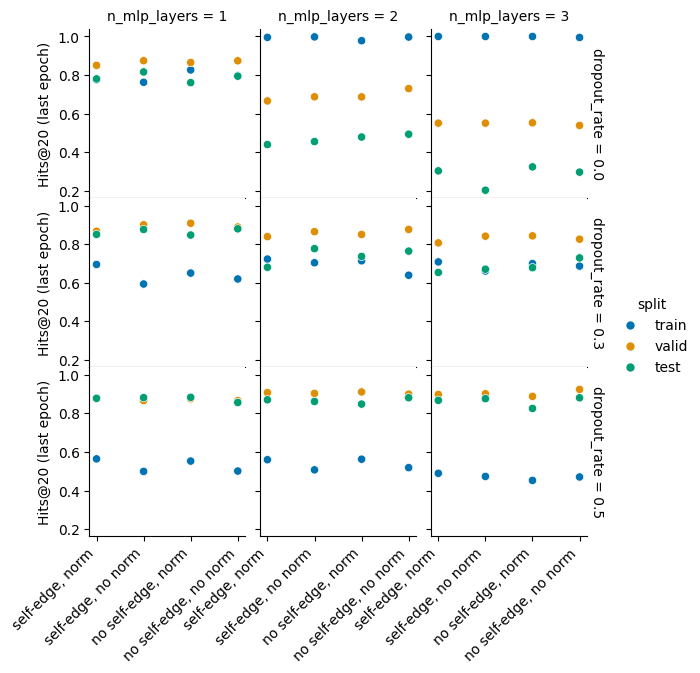

In [12]:
def conv_layer_label(row) -> str:
    if row["last_layer_self"] and row["degree_norm"]:
        return "self-edge, norm"
    if row["last_layer_self"]:
        return "self-edge, no norm"
    if row["degree_norm"]:
        return "no self-edge, norm"
    return "no self-edge, no norm"


data = sweep_results.melt(
    id_vars=list(sweep_grid),
    value_vars=["train", "valid", "test"],
    var_name="split",
    value_name="hits@20",
)
data["conv_layer"] = data.apply(conv_layer_label, axis=1)

grid = sns.relplot(
    data=data,
    x="conv_layer",
    y="hits@20",
    row="dropout_rate",
    col="n_mlp_layers",
    hue="split",
    palette="colorblind",
    facet_kws={"margin_titles": True},
    height=2,
)
grid.figure.subplots_adjust(wspace=0.1, hspace=0)
for ax in grid.axes.flat:
    for label in ax.get_xticklabels():
        label.set_rotation(45)
        label.set_ha("right")
grid.set_axis_labels("", "Hits@20 (last epoch)")
plt.show()

Learning curves of the configuration with the best validation Hits@20:

{'dropout_rate': 0.5, 'last_layer_self': False, 'degree_norm': False, 'n_mlp_layers': 3, 'test': 0.8803630471229553, 'train': 0.4701666699515449, 'valid': 0.9235895276069641}


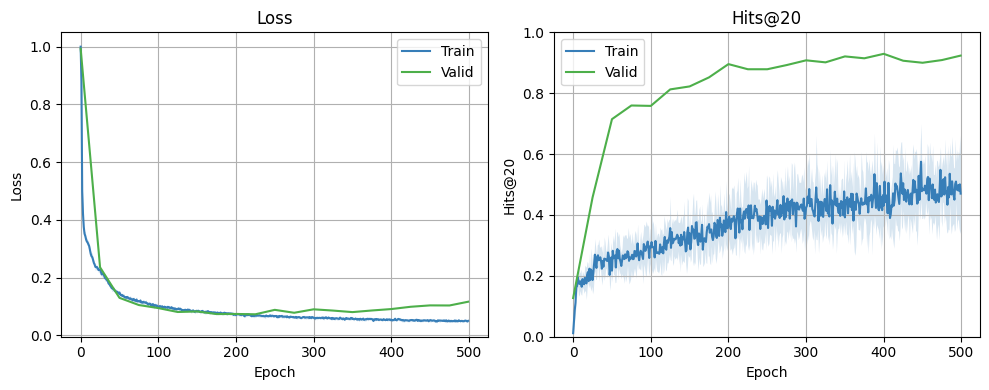

In [13]:
best = sweep_results.sort_values("valid", ascending=False).iloc[0]
print(best.drop("run").to_dict())

plot_learning(pd.read_csv(Path(SAVE_DIR) / best["run"] / "metrics.csv"))
plt.show()

## Training on a larger dataset

A random subset of 2134 drugs (half of all drugs). Set the model settings below from the sweep results above.

In [14]:
large_data = load_ddi(
    root=DATA_ROOT,
    node_limit=2134,
    generator=torch.Generator().manual_seed(42),
)
print(f"{large_data.n_nodes} drugs, {len(large_data.splits['train'].pos)} training interactions")

2134 drugs, 272504 training interactions


Epoch 500: 100%|██████████| 500/500 [14:30<00:00,  1.74s/it, hits@20: train=0.1147, valid=0.8365]


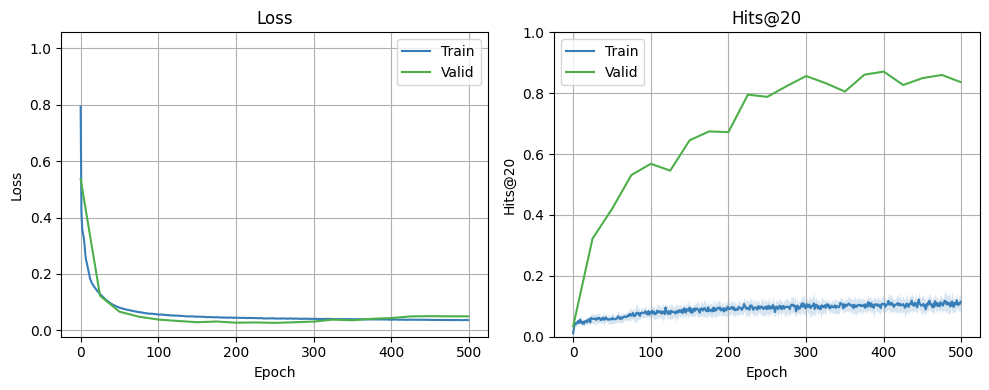

{'test': 0.7196801900863647,
 'train': 0.11465326126884012,
 'valid': 0.8364658951759338}

In [15]:
LARGE_MODEL = {
    "embedding_dim": 512,
    "dropout_rate": 0.3,
    "last_layer_self": True,
    "degree_norm": False,
    "n_mlp_layers": 2,
}

_, metrics = run(
    "larger_data",
    large_data,
    LARGE_MODEL,
    loss="auc",
    num_epochs=500,
    batch_size=16384,
    eval_every=25,
)
plot_learning(metrics)
plt.show()
summarize(metrics)